In [1]:
# Parameters
name = ""
fits_path = ""
fit_limit = 0.6
output_dir = ""  # Empty: input FITS folder / "tuned"

initial_relative_uncertainty = 0.015
target_redchi_min = 0.5
target_redchi_max = 0.99
step_factor = 1.15

mcmc_steps = 25000
mcmc_burn = 1000
mcmc_thin = 50
mcmc_walkers = 100
mcmc_workers = 1

In [2]:
# Parameters
name = "gaussian_moments_N256_L16_sigE1"
fits_path = "fits_ready/gaussian_moments_N256_L16_sigE1.fits"
fit_limit = 0.4
output_dir = "fits_ready/tuned"
initial_relative_uncertainty = 0.015
target_redchi_min = 0.5
target_redchi_max = 0.99
step_factor = 1.15
mcmc_steps = 25000
mcmc_burn = 1000
mcmc_thin = 50
mcmc_walkers = 100
mcmc_workers = 1


In [3]:
import time
start_time = time.time()

In [4]:
import numpy as np
import seaborn as sns
import pandas as pd
import sys
from pathlib import Path
import astropy.units as u
from matplotlib import pyplot as plt
import corner
import json
from astropy.io import fits
import lmfit
from lmfit.model import save_modelresult
# Add path to py_modules 
sys.path.insert(0, str(Path.cwd() / 'py_modules'))
#import strucfunc                   
import bfunc
import bplot_ideal as bplot
from reduced_chi2 import make_weights, tune_relative_uncertainty

for folder in ("Imgs", "results_fit"):
    Path(folder).mkdir(parents=True, exist_ok=True)

In [5]:
fit_limit = float(fit_limit)
initial_relative_uncertainty = float(initial_relative_uncertainty)
target_redchi_min = float(target_redchi_min)
target_redchi_max = float(target_redchi_max)
step_factor = float(step_factor)
if not np.isfinite(fit_limit) or not 0 < fit_limit <= 1:
    raise ValueError("fit_limit must be in (0, 1].")
fit_percent = int(round(100 * fit_limit))
if fit_percent < 1 or not np.isclose(100 * fit_limit, fit_percent, rtol=0, atol=1e-8):
    raise ValueError("Use whole-percent fractions, such as 0.20 or 0.99.")
if not (0 < target_redchi_min <= target_redchi_max < 1):
    raise ValueError("Require 0 < target_redchi_min <= target_redchi_max < 1.")
if not np.isfinite(initial_relative_uncertainty) or initial_relative_uncertainty <= 0:
    raise ValueError("initial_relative_uncertainty must be finite and positive.")
if not np.isfinite(step_factor) or step_factor <= 1:
    raise ValueError("step_factor must be finite and greater than 1.")

if fits_path:
    input_fits_path = Path(fits_path).expanduser()
elif name:
    input_fits_path = Path("fits_ready") / f"{name}.fits"
else:
    raise ValueError("Set name or fits_path in the parameters cell.")
if not input_fits_path.is_file():
    raise FileNotFoundError(input_fits_path)
if input_fits_path.suffix.lower() != ".fits":
    raise ValueError("This notebook expects an uncompressed .fits input.")

fit_tag = f"L{fit_percent:03d}"
output_folder = Path(output_dir).expanduser() if output_dir else input_fits_path.parent / "tuned"
output_folder.mkdir(parents=True, exist_ok=True)
output_fits_path = output_folder / f"{input_fits_path.stem}_{fit_tag}.fits"
if output_fits_path.resolve() == input_fits_path.resolve():
    raise ValueError("Output must differ from the source FITS.")
output_name = output_fits_path.stem
print(f"Input FITS:  {input_fits_path}")
print(f"Output FITS: {output_fits_path}")

Input FITS:  fits_ready\gaussian_moments_N256_L16_sigE1.fits
Output FITS: fits_ready\tuned\gaussian_moments_N256_L16_sigE1_L040.fits


### Ideal model, with the supplied observational notebook's workflow

This version preserves the template's cell sequence, weight-configuration and
`tune_relative_uncertainty` / `make_weights` calls, `result.plot_fit`, MCMC
diagnostics, `bplot.corner_plot`, and `bplot.strucfunc_plot`.
`bplot_ideal` is imported as `bplot`, so the plotting calls use your existing
three-parameter implementation. The STYLE overrides are applied when that
module exposes a STYLE dictionary. Its internal layout and saving behavior
remain controlled by your module.

Only `r0`, `sig2` and `m` are fitted (`bfunc00s`); no seeing or noise is fitted.
This notebook requires your existing `py_modules/bfunc.py`, `bplot_ideal.py`,
and `reduced_chi2.py`. Those module files were not included with the template.
The unused `fit_diagnostic_utils` import has been removed.

As in the supplied template, `K=3` and the `sig2` bounds use `B[to_fit].max()`.
The original K operation is kept exactly: it averages the first K bins into
index K, then slices at K, thus dropping the original bin at index K. This
is retained for compatibility, not silently corrected. These choices differ
from the previous fixed-uncertainty ideal notebook (K=1, full-array bounds).

The target is **reduced chi-square**, `0.5 <= result.redchi <= 0.99` by default.
The run stops before MCMC/export if the tuner does not achieve that range.
Changing assumed errors to reach this range does not independently establish
model adequacy. Unlike the fixed-uncertainty version, this deliberately tunes
the uncertainty scale separately for each fraction; posterior widths reflect
that choice. The accepted uncertainty and reduced chi-square are saved.

`mcmc_walkers` controls ensemble size; `mcmc_workers` controls parallel worker
processes. Both can be passed by the supplied Makefile. Output FITS go to
`fits_ready/tuned/` by default; plot identifiers include `_tuned_` to distinguish
these plots from fixed-uncertainty runs. Reruns replace this version's outputs.
The existing visualization notebook can select this branch using
`FILTERS["source_dir"] = "tuned"` when FITS_DIR points to `fits_ready`.

The auxiliary 1-sigma percentiles use 16 and 84 (corrected from 16 and 85).
The exported 2.5–97.5 percentile convention is unchanged.


In [6]:
with fits.open(input_fits_path) as hdul:
    hdr = hdul[0].header.copy()

sig = hdr.get("SIG", np.nan)
sig2 = hdr.get("SIG2", np.nan)
box_size = float(hdr["BOX_SIZE"])
pc = float(hdr["PC"])
pix = float(hdr["PIX"])
line = hdr.get("NAME_REG", hdr.get("LINE", input_fits_path.stem))
binsize = hdr.get("BINSIZE", 1)
if not all(np.isfinite(v) and v > 0 for v in (box_size, pc, pix)):
    raise ValueError("BOX_SIZE, PC and PIX must be finite and positive.")

In [7]:
pc_per_arcsec = pc
# Unique plot ID; fits use output_name as their NAME_ID.
data = f"{input_fits_path.stem}_tuned_{fit_tag}"

In [8]:
from astropy.table import Table
#t = Table.read(fits_path, hdu="TABLE")
#data_in = t.to_pandas()
t = Table.read(input_fits_path, hdu="TABLE")
data_in = t.to_pandas()

mask = np.array(data_in["N pairs"]) > 0
B        = np.array(data_in['Unweighted B(r)'])[mask]
r        = np.array(10 ** np.array(data_in['log10 r'])* pix * pc)[mask]
if len(r) <= 3:
    raise ValueError("Need more than three populated bins for the K=3 preprocessing.")
if not np.all(np.isfinite(r) & (r > 0) & np.isfinite(B) & (B > 0)):
    raise ValueError("Populated SF bins must have finite, positive r and B(r).")
if not np.all(np.diff(r) > 0):
    raise ValueError("SF bins must be ordered by increasing separation.")

# Fit and Confidence intervals

## Non-Linear Least-Squares Fitting

In [9]:
# Merge first K points
K = 3
r[K] = np.mean(r[:K])
B[K] = np.mean(B[:K])
r = r[K:]
B = B[K:]

In [10]:
# Weights

#relative_uncertainty = 0.015
#weights = 1.0 / (relative_uncertainty * B)
#large_scale = r > 0.3 * box_size
#weights[large_scale] /= 1.5
#weights[:1] /= 2.0

#to_fit = r <= 0.6 * box_size
#to_fit = ~large_scale

In [11]:
# Weight configuration

weight_config = dict(
    large_scale_limit=fit_limit,
    fit_limit=fit_limit,
    large_scale_factor=1.0,
    first_points_factor=1.0,
    n_first_points=1,
)

# initial_relative_uncertainty is injected from the parameters cell / Makefile.

In [12]:
to_fit = r <= weight_config["fit_limit"] * box_size
large_scale = r > weight_config["large_scale_limit"] * box_size

print(f"Fit limit: {fit_limit:.2f} x box_size")
print(f"Maximum fitted separation: {fit_limit * box_size:.5f} map length units")
print(f"Number of fitted points: {np.sum(to_fit)}")
if np.sum(to_fit) <= 3:
    raise ValueError("Need more than three fitted bins for the three-parameter ideal model.")

Fit limit: 0.40 x box_size
Maximum fitted separation: 144.81547 map length units
Number of fitted points: 35


In [13]:
model = lmfit.Model(bfunc.bfunc00s)
model.param_names

['r0', 'sig2', 'm']

In [14]:
# Same physical-parameter bounds as the supplied template.
model.set_param_hint("r0", value=0.1 * box_size, min=0.01 * box_size, max=2 * box_size)

model.set_param_hint(
    "sig2",
    value=0.5 * B[to_fit].max(),
    min=0.25 * B[to_fit].max(),
    max=2 * B[to_fit].max(),
)

model.set_param_hint("m", value=1.0, min=0.5, max=2.0)
# Ideal fit: no s0 or noise parameters.

In [15]:
pd.DataFrame(model.param_hints)

,r0,sig2,m
value,36.203867,0.186180,1.0
min,3.620387,0.093090,0.5
max,724.077344,0.744721,2.0


In [16]:
#result = model.fit(B[to_fit], weights=weights[to_fit], r=r[to_fit])

In [17]:
def fit_function(r_fit, B_fit, weights_fit):
    return model.fit(
        B_fit,
        weights=weights_fit,
        r=r_fit,
    )


result, relative_uncertainty, history = tune_relative_uncertainty(
    fit_function,
    r,
    B,
    box_size,
    initial_relative_uncertainty=initial_relative_uncertainty,
    target_redchi_min=target_redchi_min,
    target_redchi_max=target_redchi_max,
    step_factor=step_factor,
    **weight_config,
)

iter 00: relative_uncertainty = 0.01500, redchi = 5.4392
iter 01: relative_uncertainty = 0.01725, redchi = 4.1128
iter 02: relative_uncertainty = 0.01984, redchi = 3.1099
iter 03: relative_uncertainty = 0.02281, redchi = 2.3515
iter 04: relative_uncertainty = 0.02624, redchi = 1.7781
iter 05: relative_uncertainty = 0.03017, redchi = 1.3445
iter 06: relative_uncertainty = 0.03470, redchi = 1.0166
iter 07: relative_uncertainty = 0.03990, redchi = 0.7687
Accepted relative_uncertainty.


In [18]:
weights_fit, to_fit, weights, large_scale = make_weights(
    r,
    B,
    box_size,
    relative_uncertainty=relative_uncertainty,
    **weight_config,
)

print("Accepted relative_uncertainty:", relative_uncertainty)
print("Final reduced chi-square:", result.redchi)
# Do not silently accept a tuner that exhausted its iterations.
if not result.success:
    raise RuntimeError(f"Least-squares fit failed: {result.message}")
if not np.isfinite(relative_uncertainty) or relative_uncertainty <= 0:
    raise RuntimeError("Tuner returned an invalid relative uncertainty.")
if not np.isfinite(result.redchi) or not target_redchi_min <= result.redchi <= target_redchi_max:
    raise RuntimeError(
        f"Tuning did not reach [{target_redchi_min}, {target_redchi_max}]; "
        f"redchi={result.redchi}. Inspect history and reduced_chi2.py before continuing."
    )
history  # Display the tuning history in the executed notebook.

Accepted relative_uncertainty: 0.03990029820703123
Final reduced chi-square: 0.7687149363372477


[{'iteration': 0, 'relative_uncertainty': 0.015, 'redchi': 5.439200706290246},
 {'iteration': 1,
  'relative_uncertainty': 0.017249999999999998,
  'redchi': 4.112817169217636},
 {'iteration': 2,
  'relative_uncertainty': 0.019837499999999997,
  'redchi': 3.1098806572533912},
 {'iteration': 3,
  'relative_uncertainty': 0.022813124999999997,
  'redchi': 2.351516565030908},
 {'iteration': 4,
  'relative_uncertainty': 0.026235093749999994,
  'redchi': 1.7780843591916002},
 {'iteration': 5,
  'relative_uncertainty': 0.03017035781249999,
  'redchi': 1.344487228122202},
 {'iteration': 6,
  'relative_uncertainty': 0.03469591148437499,
  'redchi': 1.016625503306024},
 {'iteration': 7,
  'relative_uncertainty': 0.03990029820703123,
  'redchi': 0.7687149363372477}]

In [19]:
result

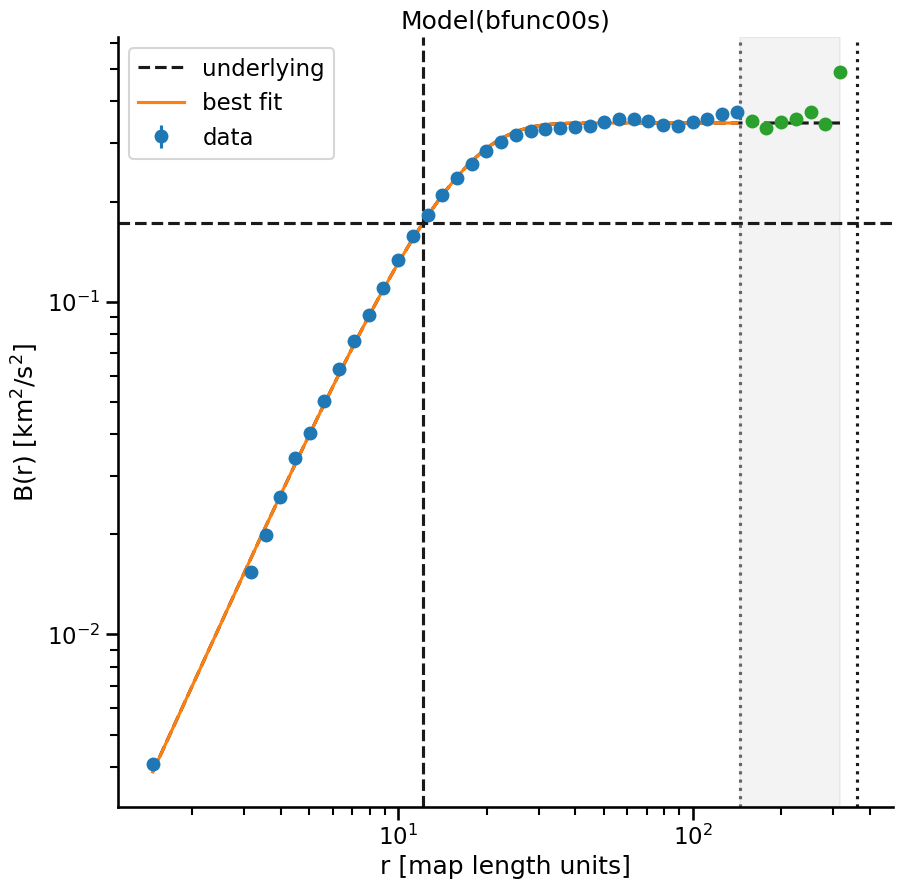

In [20]:
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the underlying model without instrumental effects
Bu = bfunc.bfunc00s(
    r, result.params["r0"].value, result.params["sig2"].value, result.params["m"].value
)
ax.plot(r, Bu, color="k", linestyle="dashed", label="underlying")

# Plot the fit results
result.plot_fit(ax=ax)

# Add in the points not included in fit
ax.plot(r[large_scale], B[large_scale], "o")

# Dotted line for box size (ideal model: no seeing marker).
ax.axvline(box_size, color="k", linestyle="dotted")

# Dashed lines for best-fit r0 and sig2
ax.axvline(result.params["r0"].value, color="k", linestyle="dashed")
ax.axhline(result.params["sig2"].value, color="k", linestyle="dashed")

# Gray box to indicate the large scale values that are excluded from the fit
if fit_limit * box_size < r[-1]:
    ax.axvspan(fit_limit * box_size, r[-1], color="k", alpha=0.05, zorder=-1)
ax.axvline(fit_limit * box_size, color="0.4", linestyle=":")

ax.set(
    xscale="log",
    yscale="log",
    xlabel="r [map length units]",
    ylabel=r"B(r) [km$^{2}$/s$^{2}$]",
)
sns.despine()

## emcee

In [21]:
# MCMC settings remain configurable from the Makefile.
settings = dict(steps=mcmc_steps, burn=mcmc_burn, thin=mcmc_thin,
                nwalkers=mcmc_walkers, workers=mcmc_workers)
for key, value in settings.items():
    if isinstance(value, bool) or not np.isfinite(float(value)) or int(value) != float(value):
        raise ValueError(f"{key} must be an integer.")
settings = {key: int(value) for key, value in settings.items()}
n_vary = sum(p.vary for p in result.params.values())
if not (settings["steps"] > settings["burn"] >= 0 and settings["thin"] >= 1
        and settings["steps"] - settings["burn"] >= settings["thin"]
        and settings["workers"] >= 1):
    raise ValueError("Invalid steps/burn/thin/workers combination.")
if settings["nwalkers"] < 2 * n_vary:
    raise ValueError(f"Use at least {2 * n_vary} walkers for {n_vary} varying parameters.")

emcee_kws = dict(**settings, is_weighted=True, progress=False)
emcee_params = result.params.copy()

In [22]:
result_emcee = model.fit(
    data=B[to_fit],
    r=r[to_fit],
    weights=weights[to_fit],
    params=emcee_params,
    method="emcee",
    nan_policy="omit",
    fit_kws=emcee_kws,
)

In [23]:
result_emcee

Text(0, 0.5, 'acceptance fraction')

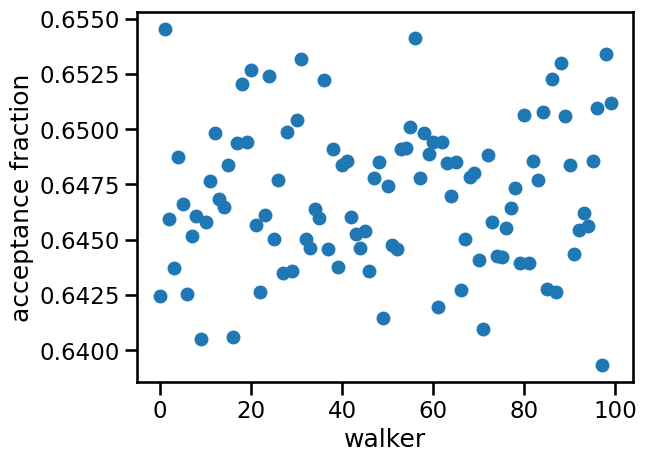

In [24]:
plt.plot(result_emcee.acceptance_fraction, "o")
plt.xlabel("walker")
plt.ylabel("acceptance fraction")



In [25]:
if hasattr(result_emcee, "acor"):
    print("Autocorrelation time for the parameters:")
    print("----------------------------------------")
    for i, p in enumerate(result_emcee.params):
        try:
            print(f"{p} = {result_emcee.acor[i]:.3f}")
        except IndexError:
            pass

Autocorrelation time for the parameters:
----------------------------------------
r0 = 38.722
sig2 = 37.968
m = 38.295


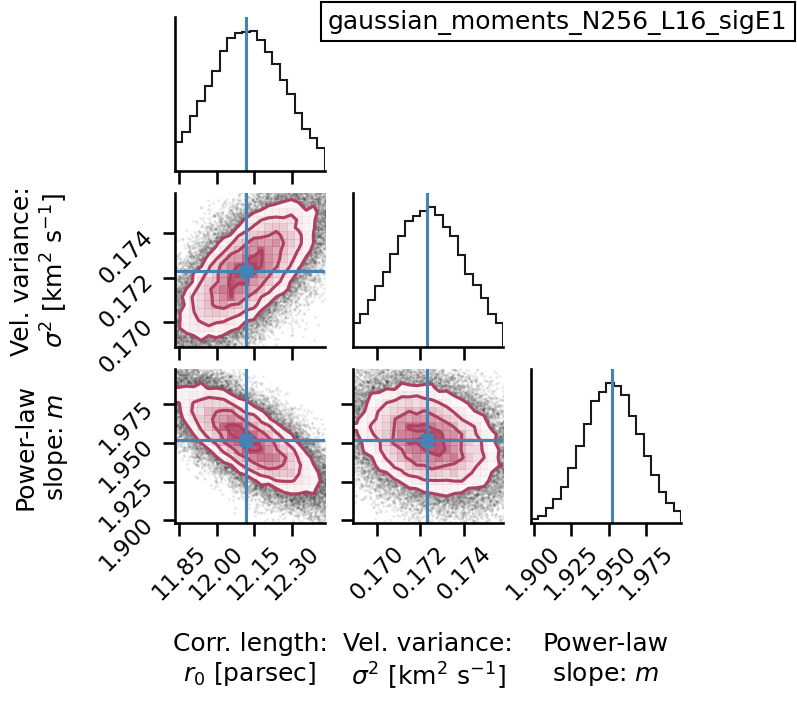

In [26]:
bplot.corner_plot(
    result_emcee, result, line, data, data_ranges=[0.95, 0.95, 0.995]
)

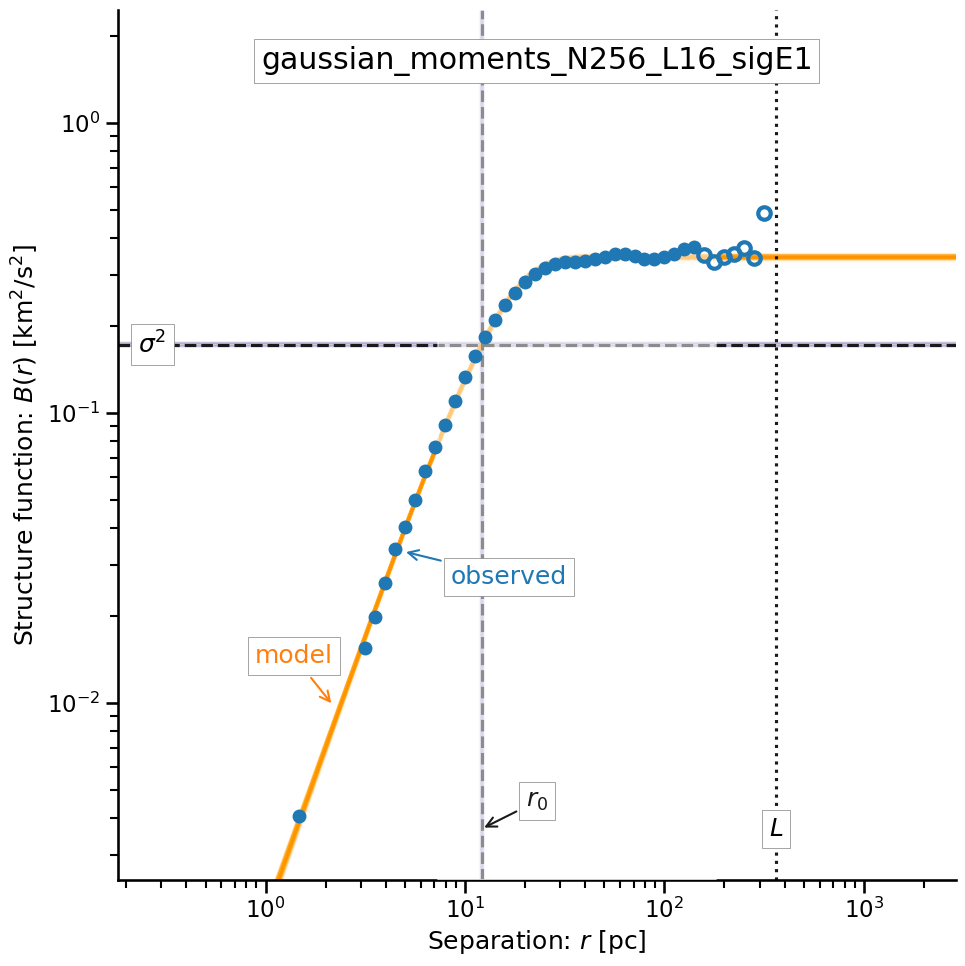

In [27]:
# Keep the supplied STYLE settings when supported by bplot_ideal.
if hasattr(bplot, "STYLE"):
    bplot.STYLE["data label element"] = 4
    bplot.STYLE["model label element"] = 0
    bplot.STYLE["model label offset"] = (-60, 40)
    bplot.STYLE["true model label element"] = 7
    bplot.STYLE["true model label offset"] = (30, -60)
bplot.strucfunc_plot(
    result_emcee, result, r, B, to_fit, line, data, box_size, large_scale
)

In [28]:
LM = {
    'sig2': [result.params['sig2'].value,result.params['sig2'].stderr],
    'r0': [result.params['r0'].value,result.params['r0'].stderr],
    'm' : [result.params['m'].value,result.params['m'].stderr],
}

In [29]:
MCMC = {
    'sig2': [result_emcee.params['sig2'].value,result_emcee.params['sig2'].stderr],
    'r0': [result_emcee.params['r0'].value,result_emcee.params['r0'].stderr],
    'm' : [result_emcee.params['m'].value,result_emcee.params['m'].stderr],
}

In [30]:
sig2s2 = np.percentile(result_emcee.flatchain['sig2'],[2.5, 97.5])
r0s2 = np.percentile(result_emcee.flatchain['r0'],[2.5, 97.5])
ms2 = np.percentile(result_emcee.flatchain['m'],[2.5, 97.5])

In [31]:
sig2s2p = sig2s2[1]-result.params['sig2'].value
sig2s2m = result.params['sig2'].value-sig2s2[0]

r0s2p = r0s2[1]-result.params['r0'].value
r0s2m = result.params['r0'].value-r0s2[0]

ms2p = ms2[1]-result.params['m'].value
ms2m = result.params['m'].value-ms2[0]

In [32]:
# MCMC approximate 1-sigma interval (16th to 84th percentiles).

sig2s1 = np.percentile(result_emcee.flatchain['sig2'],[16, 84])
r0s1 = np.percentile(result_emcee.flatchain['r0'],[16, 84])
ms1 = np.percentile(result_emcee.flatchain['m'],[16, 84])

sig2s1p = sig2s1[1]-result.params['sig2'].value
sig2s1m = result.params['sig2'].value-sig2s1[0]

r0s1p = r0s1[1]-result.params['r0'].value
r0s1m = result.params['r0'].value-r0s1[0]

ms1p = ms1[1]-result.params['m'].value
ms1m = result.params['m'].value-ms1[0]

In [33]:
#  LM + MCMC 2 sigma

results_2sig = {
    'sig2': [result.params['sig2'].value,sig2s2p,sig2s2m],
    'r0': [result.params['r0'].value,r0s2p,r0s2m],
    'm' : [result.params['m'].value,ms2p,ms2m],
    
}

results_2sig

{'sig2': [0.17231259124992873, 0.0034966582724005046, 0.003426577518963664],
 'r0': [12.118568014808346, 0.31295656815039763, 0.2842342383982661],
 'm': [1.9521675021261617, 0.03612039278593793, 0.03785520947520671]}

In [34]:
#save_modelresult(result, "results_fit/" + name + "result_ideal.sav")
#save_modelresult(result_emcee, "results_fit/" + name + "result_emcee_ideal.sav")

In [35]:
df = pd.DataFrame(results_2sig)

# Flatten MultiIndex columns
if isinstance(df.columns, pd.MultiIndex):
    df.columns = ["_".join(map(str, col)).strip() for col in df.columns.to_flat_index()]
else:
    df.columns = [str(c) for c in df.columns]

df = df.reset_index(drop=True)

t = Table.from_pandas(df)
new_hdu = fits.BinTableHDU(t, name="PARAMETERS")
new_hdu.header["ROW0"] = "LM value"
new_hdu.header["ROW1"] = "97.5 percentile minus LM"
new_hdu.header["ROW2"] = "LM minus 2.5 percentile"
new_hdu.header["CILEVEL"] = (0.95, "Central posterior interval probability")

#with fits.open(fits_path, memmap=False) as hdul:
#    hdus = [h.copy() for h in hdul]
with fits.open(input_fits_path, memmap=False) as hdul:
    hdus = [h.copy() for h in hdul]


# FITS EXTNAMEs are effectively case-insensitive; astropy reports them uppercase.
target = "PARAMETERS"
idxs = [i for i, h in enumerate(hdus) if h.name.upper() == target]

if idxs:
    i0 = idxs[0]
    # Replace the complete table; do not copy old structural column cards.
    hdus[i0] = new_hdu
    # Remove any additional duplicates if they exist
    for j in reversed(idxs[1:]):
        del hdus[j]
else:
    # If it doesn't exist, add it
    hdus.append(new_hdu)

#fits.HDUList(hdus).writeto(fits_path, overwrite=True)

hdus[0].header["FITFRAC"] = (
    fit_limit,
    "Maximum fitted separation / box size",
)

hdr_out = hdus[0].header
hdr_out["NAME_ID"] = output_name
hdr_out["FILE"] = output_fits_path.name
hdr_out["FITMODEL"] = "bfunc00s"
hdr_out["FITTUNE"] = (True, "Relative uncertainty tuned to reduced chi square")
hdr_out["RELUNC"] = (float(relative_uncertainty), "Accepted relative uncertainty")
hdr_out["RELUNCI"] = (initial_relative_uncertainty, "Initial relative uncertainty")
hdr_out["REDCHI"] = (float(result.redchi), "Accepted LM reduced chi square")
hdr_out["CHIMIN"] = target_redchi_min
hdr_out["CHIMAX"] = target_redchi_max
hdr_out["NFIT"] = int(np.sum(to_fit))
hdr_out["FITRMAX"] = fit_limit * box_size
hdr_out["MERGE_K"] = K
hdr_out["NWALKERS"] = settings["nwalkers"]
hdr_out["NWORKERS"] = settings["workers"]
hdr_out["MCMSTEP"] = settings["steps"]
hdr_out["MCMCBURN"] = settings["burn"]
hdr_out["MCMCTHIN"] = settings["thin"]
hdr_out.add_history("Ideal 3-parameter fit with tuned relative uncertainty.")
hdr_out.add_history("K=3 preprocessing and fitted-range sig2 bounds retained from template.")

# An incomplete write must not become a successful Make target.
temporary_path = output_fits_path.with_suffix(".fits.tmp")
try:
    with fits.HDUList(hdus) as output_hdul:
        output_hdul.writeto(temporary_path, overwrite=True, checksum=True)
    temporary_path.replace(output_fits_path)
finally:
    if temporary_path.exists():
        temporary_path.unlink()
print(f"Results saved to: {output_fits_path}")

Results saved to: fits_ready\tuned\gaussian_moments_N256_L16_sigE1_L040.fits


In [36]:
# Test import

from astropy.table import Table
t = Table.read(output_fits_path, hdu="PARAMETERS")
df_loaded = t.to_pandas()
df_loaded

,sig2,r0,m
0,0.172313,12.118568,1.952168
1,0.003497,0.312957,0.036120
2,0.003427,0.284234,0.037855


In [37]:
#hdul = fits.open(fits_path)
#hdr = hdul[0].header
#print(hdul.info())
#print(hdr)
with fits.open(output_fits_path) as hdul:
    hdr = hdul[0].header.copy()
    hdul.info()

print(hdr)

Filename: fits_ready\tuned\gaussian_moments_N256_L16_sigE1_L040.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      67   ()      
  1  MOM0          1 ImageHDU        37   (256, 256)   float64   
  2  MOM1          1 ImageHDU        35   (256, 256)   float64   
  3  TABLE         1 BinTableHDU     25   51R x 7C   [D, D, D, D, K, D, D]   
  4  PARAMETERS    1 BinTableHDU     21   3R x 3C   [D, D, D]   


SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                    8 / array data type                                NAXIS   =                    0 / number of array dimensions                     EXTEND  =                    T                                                  PC      =                  1.0 / Synthetic scale conversion; unity              PIX     =                  1.0 / Pixel scale in synthetic grid units            BINSIZE =                    0 / Spatial binning exponent; factor = 2**BINSIZE  BOX_SIZE=   362.03867196751236 / Full map diagonal in synthetic grid units      S0      =                  0.0 / No applied seeing                              NOISE   =                  0.0 / No added instrumental noise                    FILE    = 'gaussian_moments_N256_L16_sigE1_L040.fits' / FITS file name          MODEL   = 'gaussian'           / Input covariance model                         M3D     =                  2.0 / Input m

In [38]:
print("--- %s seconds ---" % (time.time() - start_time))

--- 107.10643172264099 seconds ---
